In [3]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)

df = iris.frame.copy()

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [4]:
print(df.shape)
print(df.columns) #name der spalten
print(df.info())

(150, 5)
Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'target'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB
None


In [ ]:
print(df.info()) #Zeige mit einer Pandas-Methode die allgemeinen Informationen des DataFrames an.
print(df.dtypes)#Gib die Datentypen aller Spalten aus
print(df["sepal length (cm)"].dtype) #Wähle die Spalte `sepal length (cm)` aus und ermittle nur ihren Datentyp.
print(df.tail(3)) #Lass dir mit `tail()` die letzten 3 Zeilen anzeigen.

In [19]:
print("mean:", df["petal length (cm)"].mean())
print("median:", df["petal length (cm)"].median())
print("minimum:", df["petal length (cm)"].min())
print("maximum:",df["petal length (cm)"].max())
print("standardabweichung:", df["petal length (cm)"].std())
print( df.describe())



mean: 3.7580000000000005
median: 4.35
minimum: 1.0
maximum: 6.9
standardabweichung: 1.7652982332594662
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)      target  
count        150.000000  150.000000  
mean           1.199333    1.000000  
std            0.762238    0.819232  
min            0.100000    0.000000  
25%            0.300000    0.000000  
50%            1.300000    1.000000  
75%            1.800000    2.000000  
max    

In [33]:
print("mean:", df["sepal length (cm)"].mean())
print("median:", df["sepal length (cm)"].median())
#wenn MW deutlich größer as median dann ist es eine rechtsschiefe verteilung
#df.groupby("sepal length (cm)")["target"].mean()

mean: 5.843333333333334
median: 5.8


#GROUPBY

In [28]:

print("groupby std:", df.groupby("target")["sepal length (cm)"].std())
print("groupby mean:",df.groupby("target")["sepal length (cm)"].mean())
print("groupby median:", df.groupby("target")["sepal length (cm)"].median())

groupby std: target
0    0.352490
1    0.516171
2    0.635880
Name: sepal length (cm), dtype: float64
groupby mean: target
0    5.006
1    5.936
2    6.588
Name: sepal length (cm), dtype: float64
groupby median: target
0    5.0
1    5.9
2    6.5
Name: sepal length (cm), dtype: float64


Lektion 5: Aggregation mit .agg()

In [40]:
print(df.groupby("target")["petal length (cm)"].agg(["mean", "median", "std"]))
#sepal
print(df.groupby("target")["sepal length (cm)"].agg(["mean", "median", "std"]))

         mean  median       std
target                         
0       1.462    1.50  0.173664
1       4.260    4.35  0.469911
2       5.552    5.55  0.551895
         mean  median       std
target                         
0       5.006     5.0  0.352490
1       5.936     5.9  0.516171
2       6.588     6.5  0.635880


Lektion 6: Filtering & Boolean Indexing

In [52]:
df_long= df[df["petal length (cm)"] > 5]
print(df_long.head())
print(df_long.groupby("target")["petal length (cm)"].agg(["mean","median","std"]))
print("_____shape:", df_long.shape)

     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
83                 6.0               2.7                5.1               1.6   
100                6.3               3.3                6.0               2.5   
101                5.8               2.7                5.1               1.9   
102                7.1               3.0                5.9               2.1   
103                6.3               2.9                5.6               1.8   

     target  
83        1  
100       2  
101       2  
102       2  
103       2  
            mean  median       std
target                            
1       5.100000     5.1       NaN
2       5.702439     5.6  0.489126
_____shape: (42, 5)


Lektion 7: Mehrere Bedingungen kombinieren

In [76]:
df_filtered = df[
    (df["petal length (cm)"] > 5) &
    (df["sepal length (cm)"] > 6) 
]

#print(df_filtered)
print(df_filtered.head())
print(df_filtered.groupby("target").size())
print( df_filtered.info())
print( df_filtered.describe())



     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
100                6.3               3.3                6.0               2.5   
102                7.1               3.0                5.9               2.1   
103                6.3               2.9                5.6               1.8   
104                6.5               3.0                5.8               2.2   
105                7.6               3.0                6.6               2.1   

     target  
100       2  
102       2  
103       2  
104       2  
105       2  
target
2    37
dtype: int64
<class 'pandas.DataFrame'>
Index: 37 entries, 100 to 148
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  37 non-null     float64
 1   sepal width (cm)   37 non-null     float64
 2   petal length (cm)  37 non-null     float64
 3   petal width (cm)   37 non-null     float64
 4   target             

# Lektion 8: Zeilen und Spalten auswählen – loc und iloc
Quelle: AHMS_ML_EDA.pdf – Seiten 29–34

### Allgemeine Syntax ###

df.loc[zeilen_labels, spalten_labels]
df.iloc[zeilen_positionen, spalten_positionen]

### 2. Slicing verstehen ###

Mit : kannst du Bereiche auswählen.

df.iloc[0:5, 0:2]

- loc arbeitet mit Index-Labels (Bezeichnungen).

iloc arbeitet mit Positionen (numerischer Reihenfolge).
Warum?
- iloc schließt die obere Grenze des Slice aus.
- loc schließt die obere Grenze bei einem Label-Slice ein, sofern das Endlabel existiert.

In [94]:
#1.
print(df.iloc[0:10, 0:3])
#2
df_subset= df.loc[10:20, ["sepal length (cm)", "petal length (cm)"]]
print(df_subset)

print(df.loc[5])

print(df.iloc[5])

   sepal length (cm)  sepal width (cm)  petal length (cm)
0                5.1               3.5                1.4
1                4.9               3.0                1.4
2                4.7               3.2                1.3
3                4.6               3.1                1.5
4                5.0               3.6                1.4
5                5.4               3.9                1.7
6                4.6               3.4                1.4
7                5.0               3.4                1.5
8                4.4               2.9                1.4
9                4.9               3.1                1.5
    sepal length (cm)  petal length (cm)
10                5.4                1.5
11                4.8                1.6
12                4.8                1.4
13                4.3                1.1
14                5.8                1.2
15                5.7                1.5
16                5.4                1.3
17                5.1             

# Lektion 9: Sorting – Daten sortieren
- dataframe.sort_values(by="spaltenname", ascending=True)
Bestandteil	Bedeutung
- sort_values()	Methode zum Sortieren
- by	Nach welcher Spalte sortieren?
- ascending=True	Aufsteigend, klein nach groß
- ascending=False	Absteigend, groß nach klein


In [102]:
df_sorted= df.sort_values(by="petal length (cm)", ascending= False)
#print("sorted:", df_sorted)
print(df_sorted.head())

print(df_sorted.iloc[0]) 
#wählt die erste Zeile nach der Sortierung aus. Das ist die Blume mit dem ursprünglichen Index 118.

print(df_sorted.loc[0])
#loc[0] sucht nach dem Index-Label 0, unabhängig davon, wo diese Zeile nach der Sortierung steht.

     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
118                7.7               2.6                6.9               2.3   
122                7.7               2.8                6.7               2.0   
117                7.7               3.8                6.7               2.2   
105                7.6               3.0                6.6               2.1   
131                7.9               3.8                6.4               2.0   

     target  
118       2  
122       2  
117       2  
105       2  
131       2  
sepal length (cm)    7.7
sepal width (cm)     2.6
petal length (cm)    6.9
petal width (cm)     2.3
target               2.0
Name: 118, dtype: float64
sepal length (cm)    5.1
sepal width (cm)     3.5
petal length (cm)    1.4
petal width (cm)     0.2
target               0.0
Name: 0, dtype: float64


# Lektion 10: Duplicates – Doppelte Daten erkennen

Wenn es sich tatsächlich um eine versehentliche doppelte Erfassung handelt, könnte das unsere Statistiken verzerren.

# # A. Duplikate erkennen # #
dataframe.duplicated()

Diese Methode gibt eine boolesche Series zurück.

Standardmäßig wird das erste Vorkommen einer Zeile mit False und jedes weitere identische Vorkommen mit True markiert.

# # B. Boolesche Werte zählen # # 
werte = [True, False, True, True]
print(sum(werte))

# # C. Duplikate entfernen # # 
dataframe.drop_duplicates()



In [109]:
print(df.duplicated())
df_bool=df.duplicated()
print("Es kommen", sum(df_bool), "Duplikate vor. ")

df_unique= df.drop_duplicates()
print(df.shape)
print(df_unique.shape)

0      False
1      False
2      False
3      False
4      False
       ...  
145    False
146    False
147    False
148    False
149    False
Length: 150, dtype: bool
Es kommen 1 Duplikate vor. 
(150, 5)
(149, 5)


// NOTE //
Falls wir die Indizes anschließend neu nummerieren möchten, gibt es eine weitere Methode:
dataframe.reset_index(drop=True)
 # # Lektion 11: Missing Values – Fehlende Werte # # 
NaN steht für Not a Number.

 # #  A. Fehlende Werte erkennen # #
- dataframe.isna()
Gibt einen DataFrame mit booleschen Werten zurück:
- True → Wert fehlt.
- False → Wert ist vorhanden.

 # # B. Fehlende Werte zählen# # 

dataframe.isna().sum()
Wir summieren die True-Werte. Bei einem DataFrame berechnet .sum() standardmäßig die Summe für jede Spalte.

# # C. Fehlende Werte erzeugen # #

import numpy as np
dataframe.loc[index_label, "spaltenname"] = np.nan

In [119]:
import numpy as np

df_missing = df.copy()
df_missing.loc[0, "sepal length (cm)"] = np.nan

df_missing.loc[5, "petal width (cm)"] = np.nan
print(df_missing.shape)
print(df_missing.isna().sum())
print(df_missing.head(5))

(150, 5)
sepal length (cm)    1
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     1
target               0
dtype: int64
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                NaN               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  


# Lektion 12: Missing Values analysieren

werte = [True, False, False, True, False]

Wenn du davon den Mittelwert berechnest:
\[
\frac{1+0+0+1+0}{5}=0{,}4
\]

Das bedeutet: 40 % der Werte sind True.



In [128]:
print((df_missing.isna().mean()))
missing_percentage= (df_missing.isna().mean())*100
print(missing_percentage)

sepal length (cm)    0.006667
sepal width (cm)     0.000000
petal length (cm)    0.000000
petal width (cm)     0.006667
target               0.000000
dtype: float64
sepal length (cm)    0.666667
sepal width (cm)     0.000000
petal length (cm)    0.000000
petal width (cm)     0.666667
target               0.000000
dtype: float64


dataframe["spaltenname"].isna()

In [160]:
df_nan= df_missing[df_missing["sepal length (cm)"].isna()]
print(df_nan)

print(df_nan.shape)
print(df_missing.isna().any(axis=1))

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                NaN               3.5                1.4               0.2   

   target  
0       0  
(1, 5)
0       True
1      False
2      False
3      False
4      False
       ...  
145    False
146    False
147    False
148    False
149    False
Length: 150, dtype: bool


# # Zeilen asugeben mit nan # #

In [141]:
df_any_nan= df_missing[df_missing.isna().any(axis=1)]
print(df_any_nan)

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                NaN               3.5                1.4               0.2   
5                5.4               3.9                1.7               NaN   

   target  
0       0  
5       0  


# Lektion 14: dropna() – Fehlende Werte entfernen

- Variante A: Zeilen mit fehlenden Werten entfernen

    neuer_df = dataframe.dropna()

Standardmäßig werden alle Zeilen entfernt, die mindestens einen fehlenden Wert enthalten.

- Variante B: Spalten mit fehlenden Werten entfernen
   
    neuer_df = dataframe.dropna(axis=1)
Hier werden alle Spalten entfernt, die mindestens einen fehlenden Wert enthalten.

- Variante C: Nur vollständig leere Zeilen entfernen

    neuer_df = dataframe.dropna(how="all")
Hier wird eine Zeile nur entfernt, wenn alle ihre Werte fehlen.

In [143]:
df_drop_rows = df_missing.dropna()
print(df_drop_rows)

df_drop_col = df_missing.dropna(axis=1)
print(df_drop_col)

print(df_drop_rows.shape)
print(df_drop_col.shape)

     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
1                  4.9               3.0                1.4               0.2   
2                  4.7               3.2                1.3               0.2   
3                  4.6               3.1                1.5               0.2   
4                  5.0               3.6                1.4               0.2   
6                  4.6               3.4                1.4               0.3   
..                 ...               ...                ...               ...   
145                6.7               3.0                5.2               2.3   
146                6.3               2.5                5.0               1.9   
147                6.5               3.0                5.2               2.0   
148                6.2               3.4                5.4               2.3   
149                5.9               3.0                5.1               1.8   

     target  
1         0  

2. Die neue Python-Syntax
A. Einen fehlenden Wert durch eine Zahl ersetzen
dataframe["spalte"].fillna(wert)

dataframe["spalte"].fillna(
    dataframe["spalte"].methode()
)

In [159]:
df_imputed =  df_missing.copy()

meanS= df_imputed["sepal length (cm)"].mean()
df_imputed["sepal length (cm)"]= df_imputed["sepal length (cm)"].fillna(meanS)

medianP=df_imputed["petal width (cm)"].median()
df_imputed["petal width (cm)"]= df_imputed["petal width (cm)"].fillna(medianP)

print(df_imputed.isna().sum())
print(df_imputed.shape)

print(df_imputed.head())

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64
(150, 5)
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0           5.848322               3.5                1.4               0.2   
1           4.900000               3.0                1.4               0.2   
2           4.700000               3.2                1.3               0.2   
3           4.600000               3.1                1.5               0.2   
4           5.000000               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  


MCAR

Missing Completely At Random

MAR

Missing At Random

MNAR

Missing Not At Random

# Eine neue Spalte erstellen
df["neue_spalte"] = ausdruck

# Nach Gruppen zählen
df.groupby("kategorie")["bool_spalte"].sum()

In [165]:
df_missing["missing_sepal"] = df_missing["sepal length (cm)"].isna()

df_missing.groupby("target")["missing_sepal"].sum()

target
0    1
1    0
2    0
Name: missing_sepal, dtype: int64

# # Missingno – Fehlende Werte visualisieren # #

 matrix()	Zeigt, wo einzelne Werte fehlen
bar()	Zeigt die Vollständigkeit jeder Spalte
heatmap()	Zeigt Zusammenhänge zwischen Fehlwertmustern
dendrogram()	Gruppiert Spalten mit ähnlichen Fehlwertmustern

<Axes: >

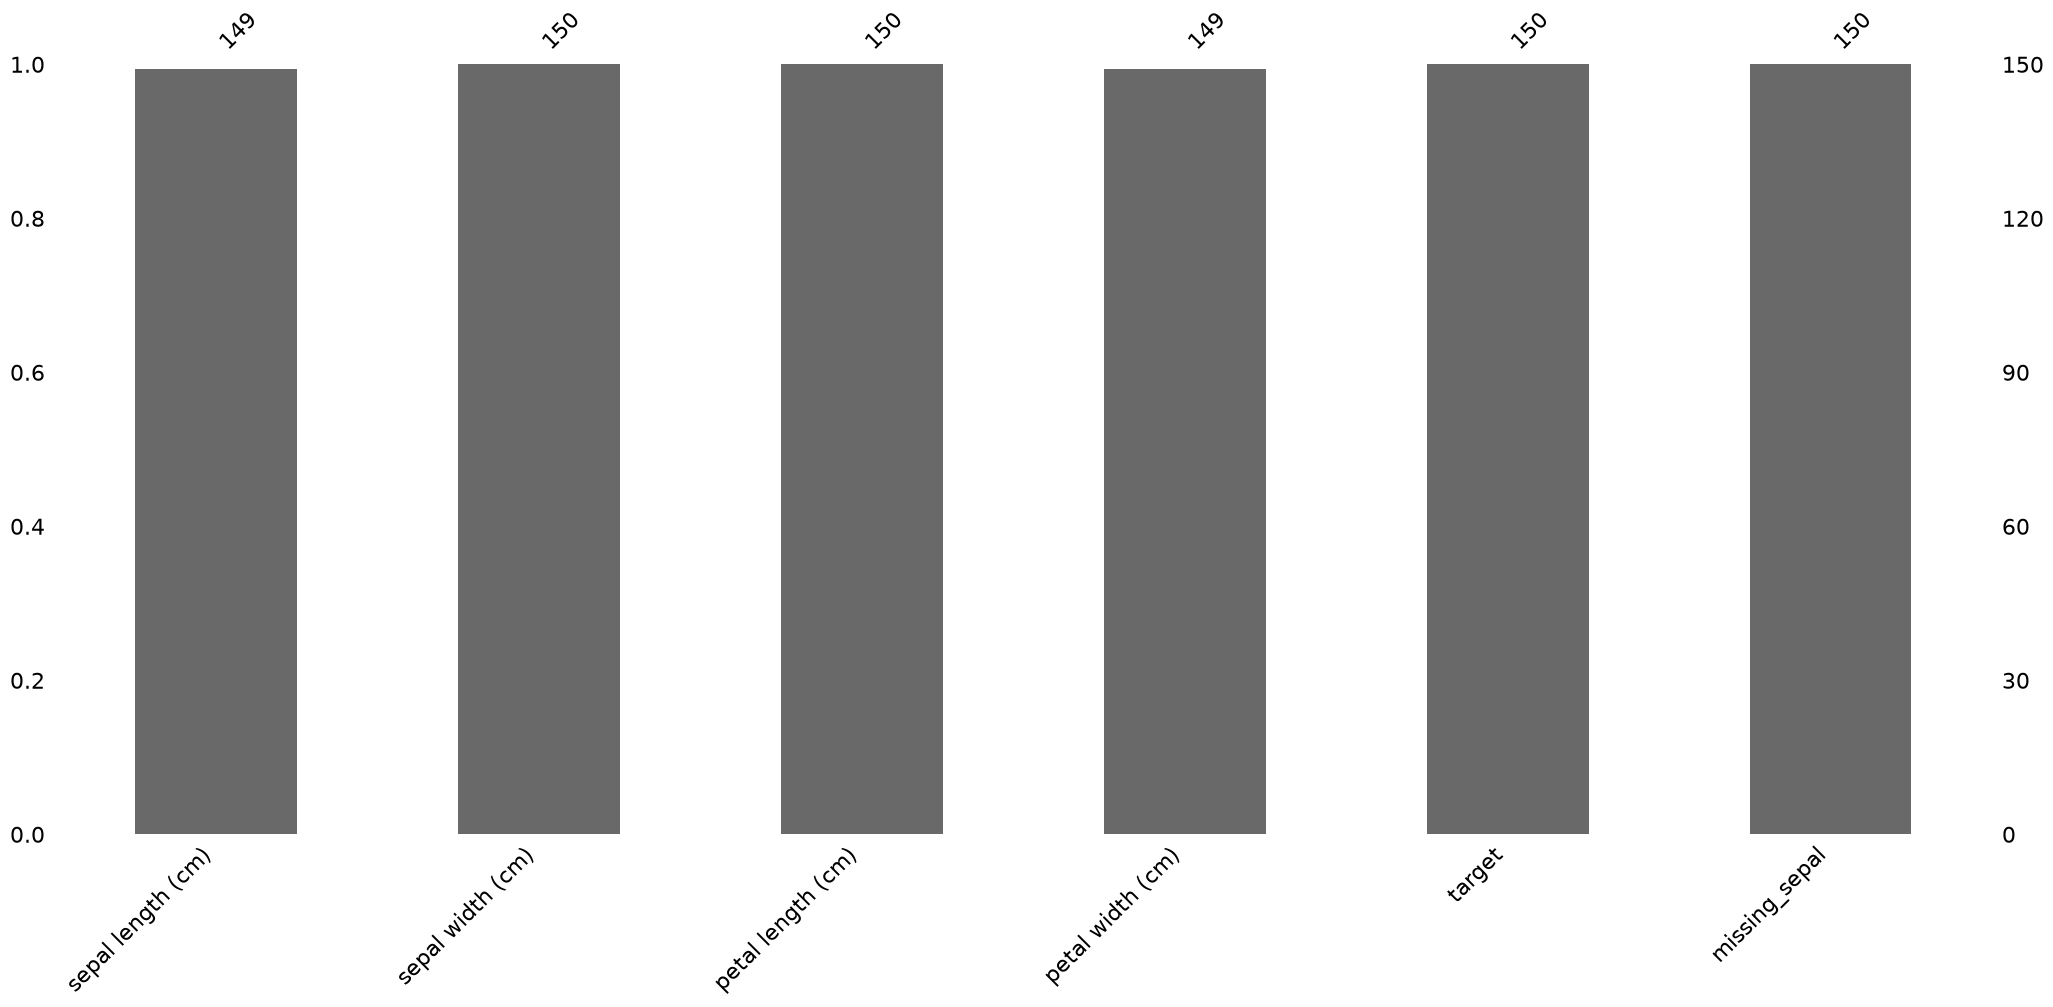

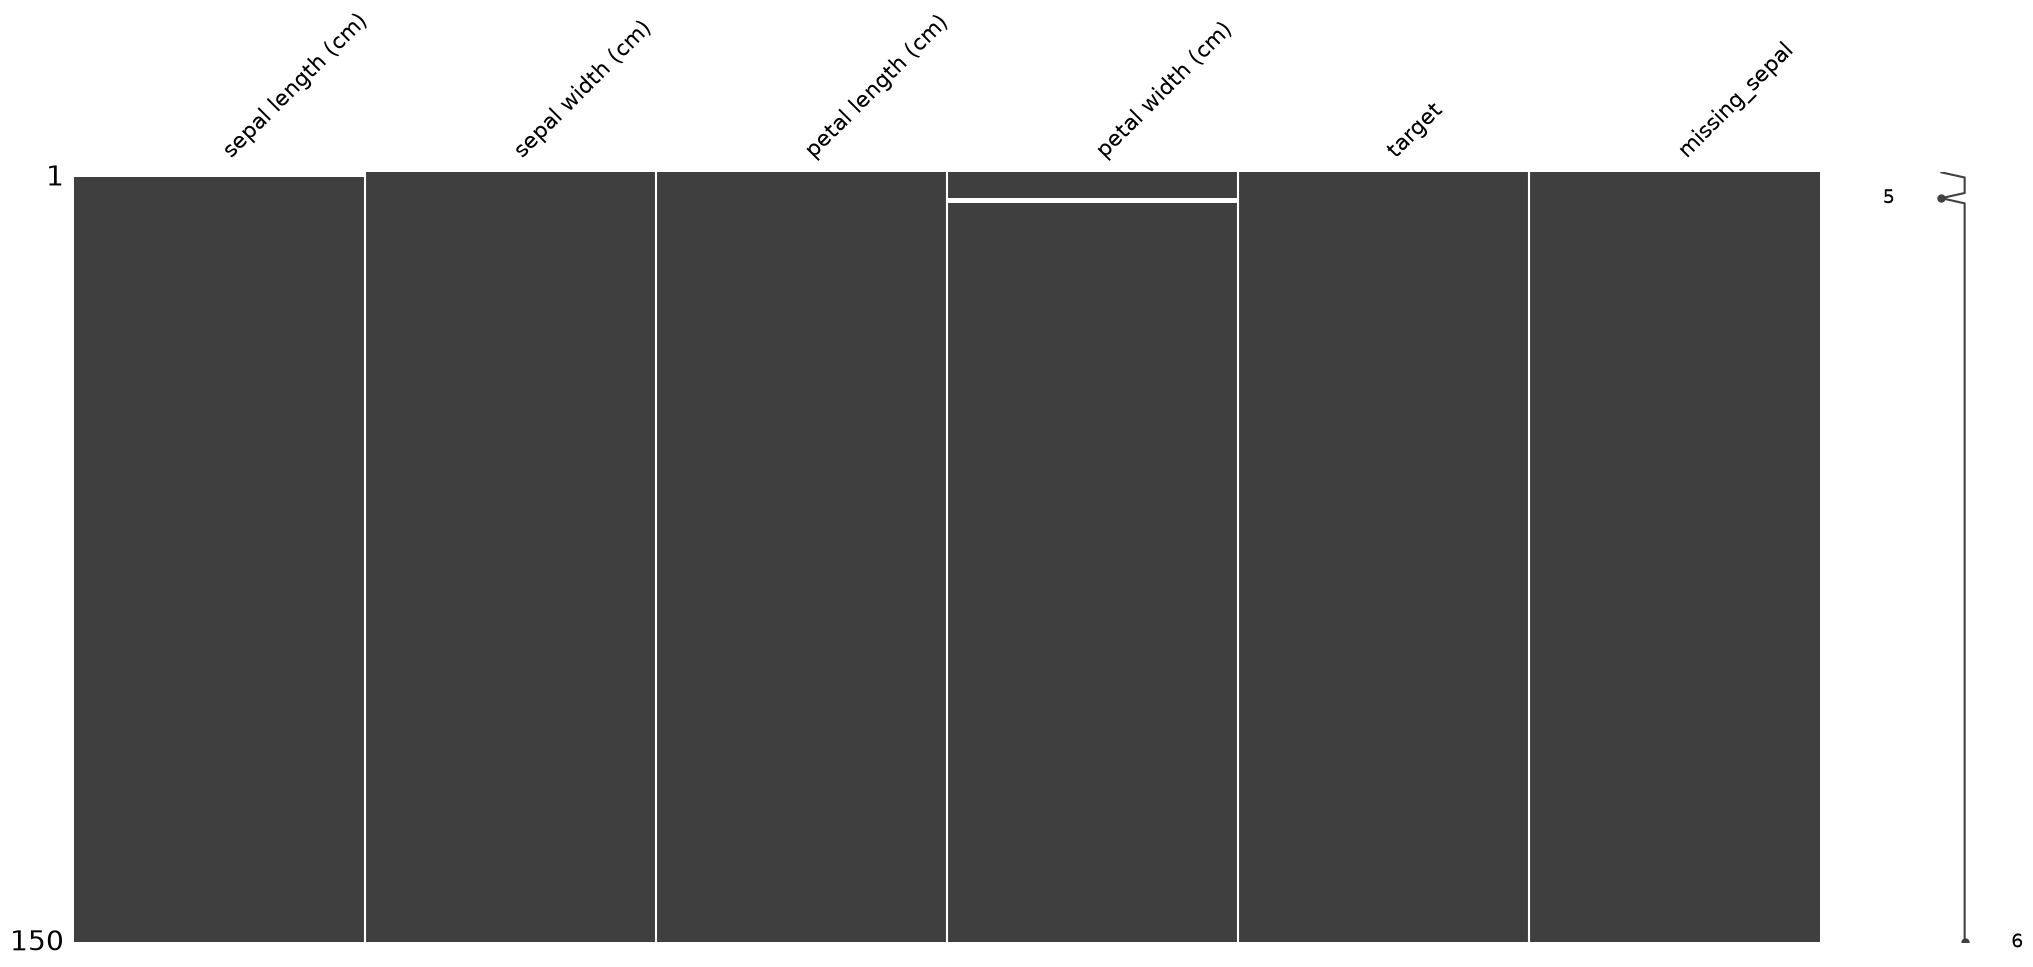

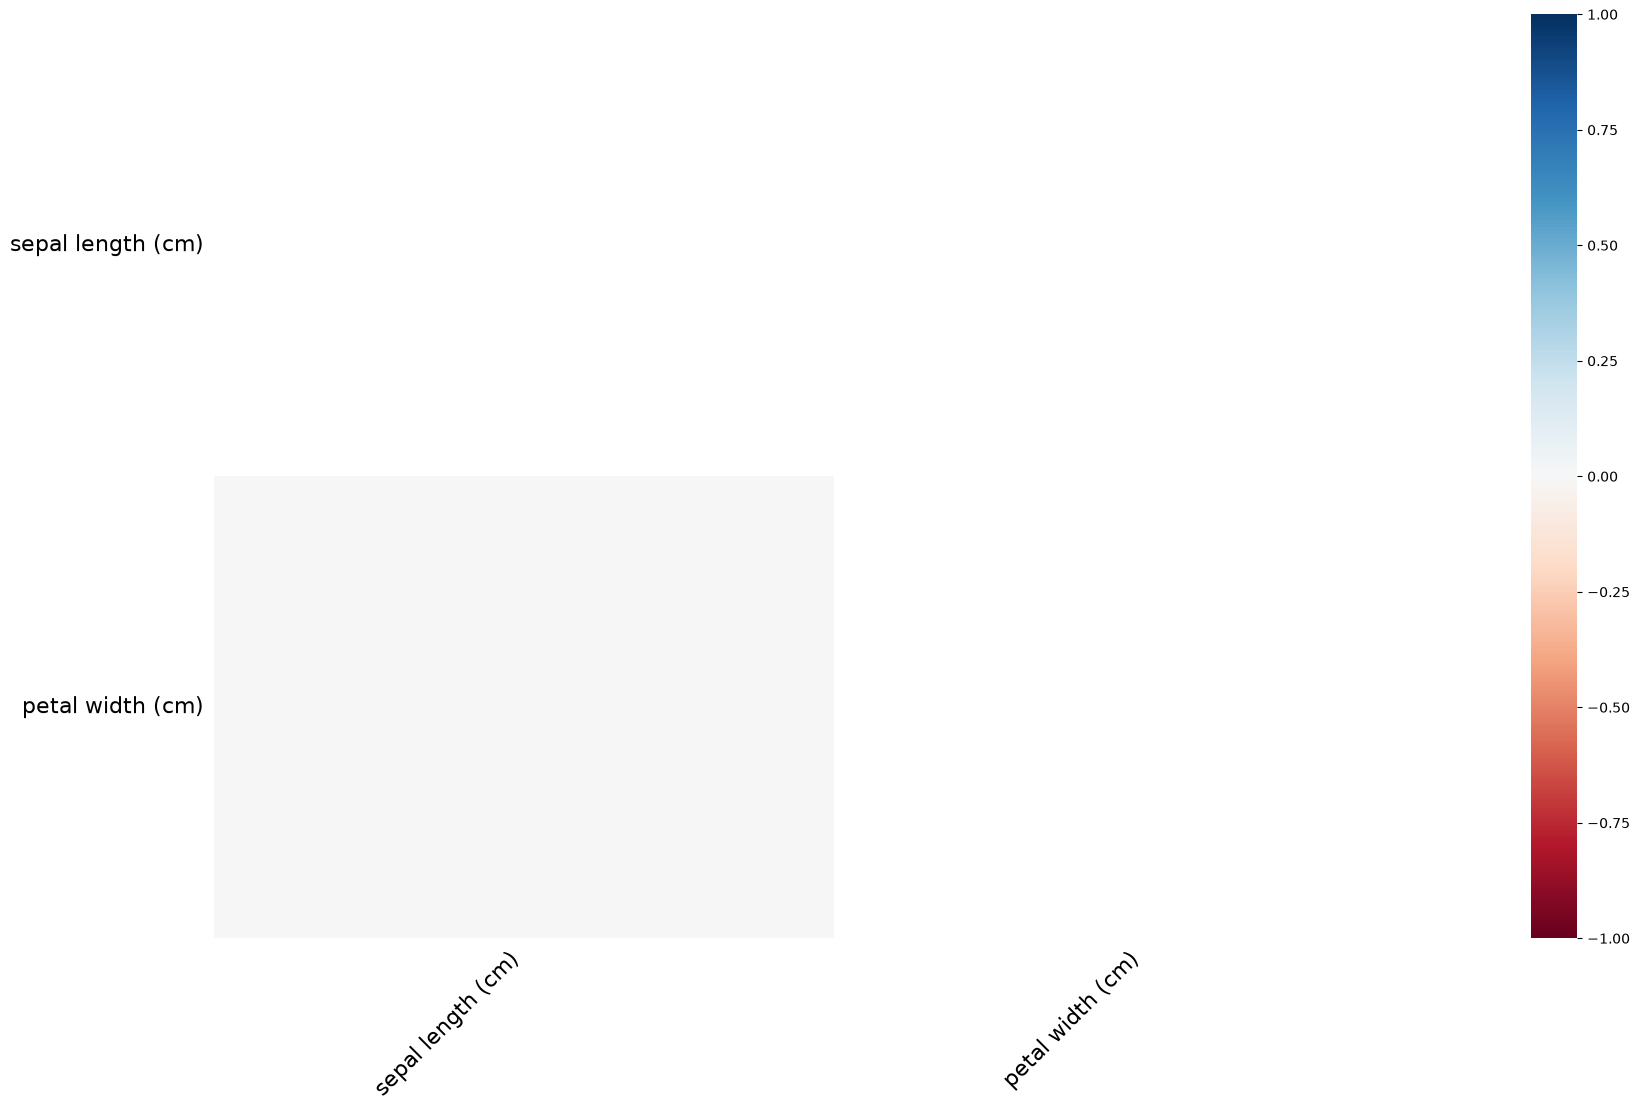

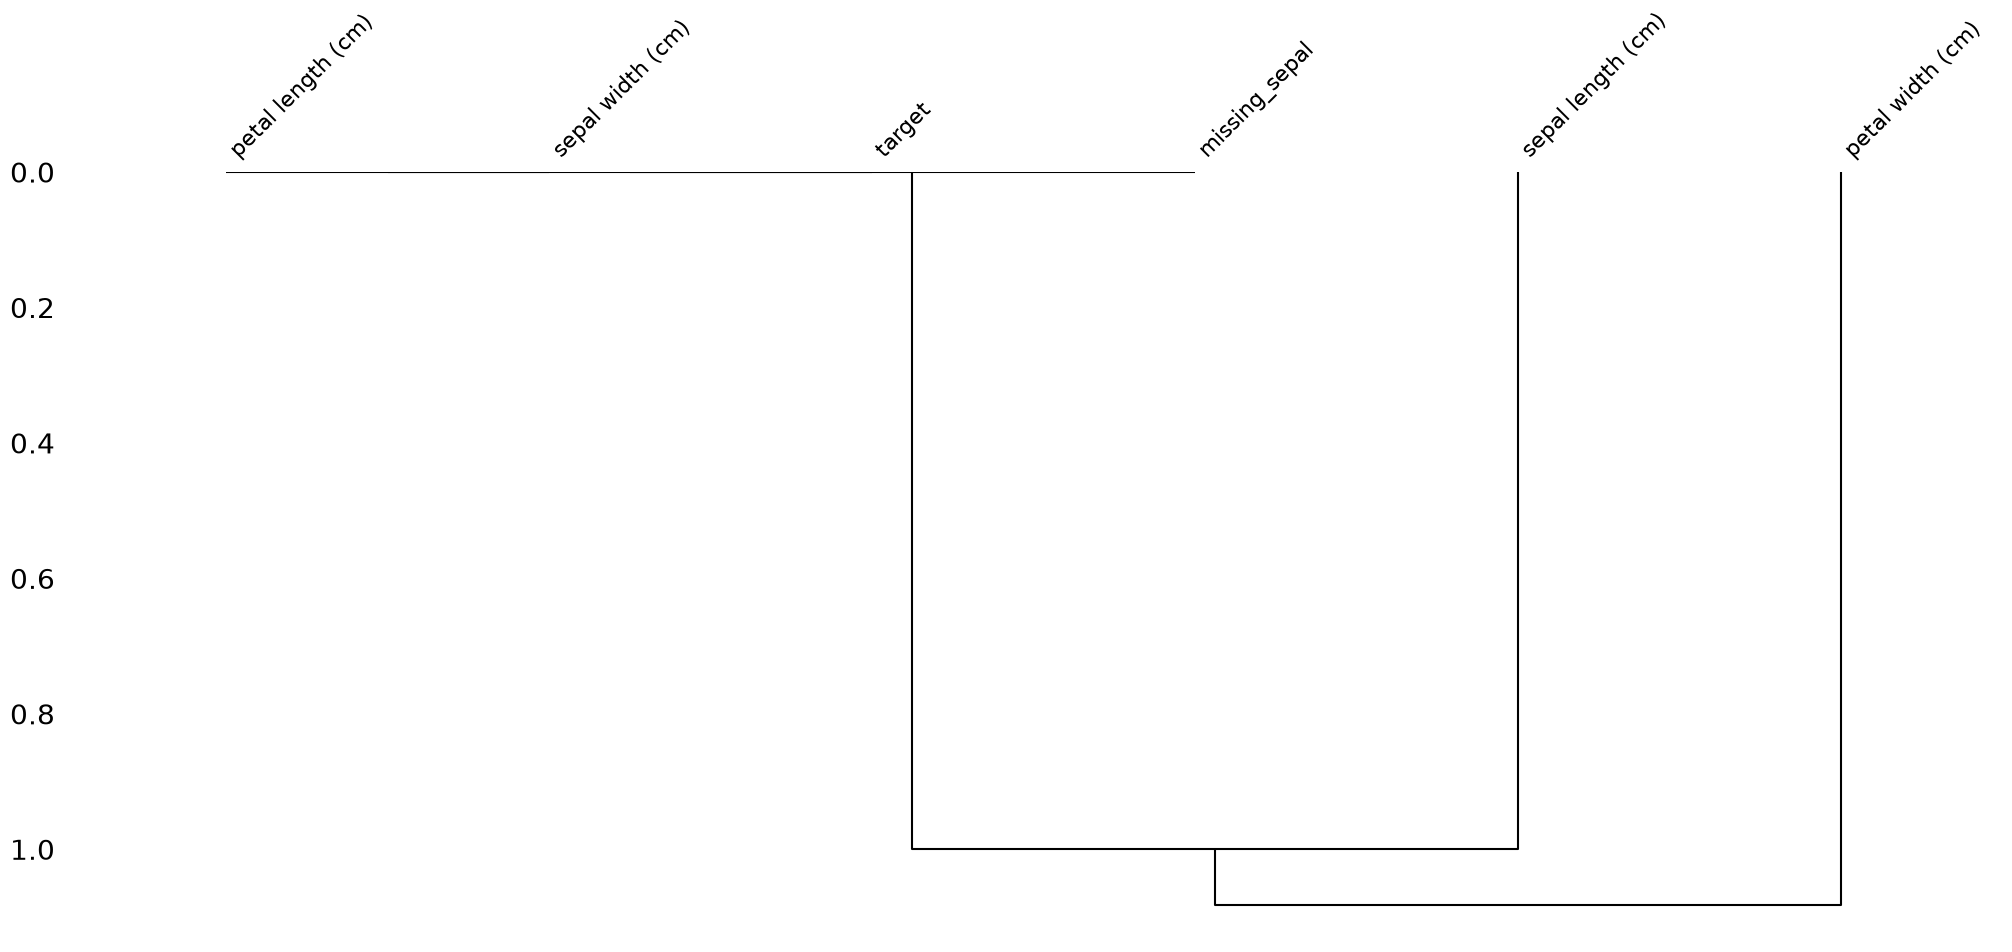

In [172]:
import missingno as msno


msno.bar(df_missing)
msno.matrix(df_missing)
msno.heatmap(df_missing)
msno.dendrogram(df_missing)

# Lektion 18: Outlier Detection – Ausreißer erkennen

- Statistischer Ausreißer: Ein Wert ist im Vergleich zur Verteilung ungewöhnlich.
- Unplausibler Wert: Ein Wert ist aufgrund unseres Fachwissens offensichtlich falsch oder nicht sinnvoll.

import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=dataframe["spaltenname"])
plt.show()

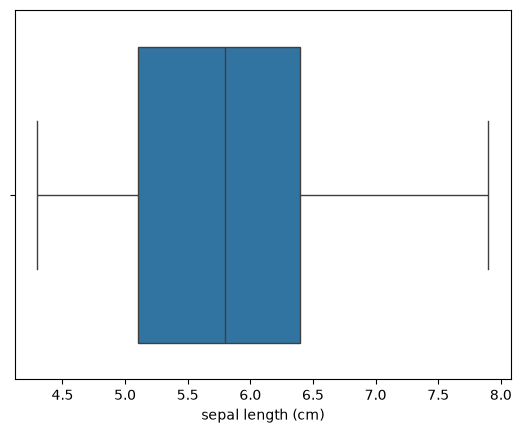

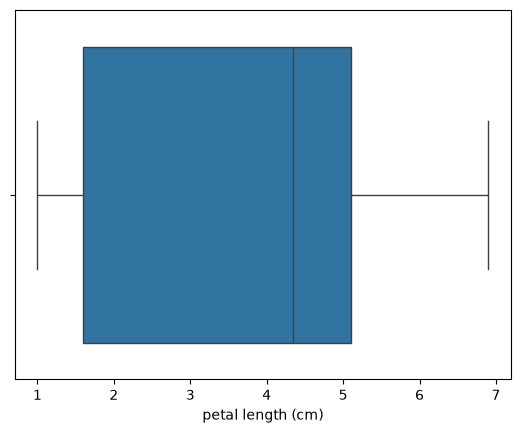

In [175]:

import seaborn as sns
import matplotlib.pyplot as plt

df_missing["sepal length (cm)"].describe()

sns.boxplot(x=df_missing["sepal length (cm)"])
plt.show()

sns.boxplot(x=df_missing["petal length (cm)"])
plt.show()